In [1]:
!pip install -q -U transformers accelerate

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import re
import json
import glob
import time
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from scipy.stats import spearmanr
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [2]:
MODEL_NAME = "Qwen/Qwen2.5-VL-7B-Instruct"

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=256 * 28 * 28,
    max_pixels=1024 * 28 * 28,
)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={0: "12GiB", 1: "12GiB"},
    attn_implementation="sdpa",
)
DT = torch.float16
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

lm = model.model.language_model
lm_head = model.lm_head
layers = lm.layers
n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = layers[0].self_attn.o_proj.in_features // n_head
IMAGE_TOKEN_ID = model.config.image_token_id
assert len(layers) == n_layer
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim, image token id", IMAGE_TOKEN_ID, "| attention", model.config.text_config._attn_implementation)

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

28 language model layers, 28 heads, 128 head dim, image token id 151655 | attention sdpa


In [3]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"

HALLU_TYPES = ["attribute", "relation"]
SHARD = 0
N_SHARDS = 1
N_UNITS = {"attribute": 100, "relation": 100}
DRIVEN_TE = -1.0
SLUG = f"{USERNAME}/patch-qwen-paths"
DIRECTIONS = ["noising"]
MAX_HOURS = 9.0
PILOT_UNITS = 1
BATCH_SAVE_SIZE = 20
UPLOAD_EVERY = 2
CHECK_TOL = 0.25
TAIL_N = 5
GROUPS = ["visual", "text", "tail"]
OUT_DIR = "/kaggle/working/patch_qwen_paths"
os.makedirs(OUT_DIR, exist_ok=True)

FIXED_SENDERS = [
    ("head", 15, 26, "text"), ("mlp", 15, -1, "all"), ("head", 20, 2, "all"), ("mlp", 1, -1, "visual"), ("mlp", 14, -1, "all"), ("head", 18, 4, "all"), ("mlp", 16, -1, "all"),
]
ROUTERS = [("head", 15, 26, "text"), ("mlp", 15, -1, "all"), ("mlp", 1, -1, "visual")]
WINDOWS = {"0_14": range(0, 15), "15_16": range(15, 17), "17_18": range(17, 19), "19_21": range(19, 22), "22_27": range(22, 28)}
SETS = {
    "direct": {"mlp": set(), "heads": False},
    "mlp_all": {"mlp": set(range(28)), "heads": False},
    "heads_all": {"mlp": set(), "heads": True},
}
for wname, wr in WINDOWS.items():
    SETS[f"heads_{wname}"] = {"mlp": set(wr), "heads": True}
SETS["total"] = {"mlp": set(range(28)), "heads": True}
SET_NAMES = list(SETS)


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    return processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, DT)


VG_LOCAL = {}
if True:
    VG_DATASET = "sajjad2goudarzi/the-visual-genome-dataset"
    vg_roots = {d_ for d_ in (f"/kaggle/input/datasets/{VG_DATASET}", f"/kaggle/input/{VG_DATASET.split(chr(47))[1]}") if os.path.isdir(d_)}
    for pat in ["/kaggle/input/*", "/kaggle/input/*/*", "/kaggle/input/datasets/*/*"]:
        for d_ in glob.glob(pat):
            name = os.path.basename(d_).lower()
            if os.path.isdir(d_) and ("genome" in name or name.startswith("vg") or name.startswith("visualgenome")):
                vg_roots.add(d_)
    for pat in ["/kaggle/input/*/VG_100K*", "/kaggle/input/*/*/VG_100K*", "/kaggle/input/*/*/*/VG_100K*", "/kaggle/input/datasets/*/*/VG_100K*", "/kaggle/input/datasets/*/*/*/VG_100K*"]:
        vg_roots.update(d_ for d_ in glob.glob(pat) if os.path.isdir(d_))
    for root_ in sorted(vg_roots):
        for dp, dn, fns in os.walk(root_):
            for fn in fns:
                if fn.lower().endswith(".jpg") and fn[:-4].isdigit():
                    VG_LOCAL[fn[:-4]] = os.path.join(dp, fn)
    print(len(VG_LOCAL), "Visual Genome images found in attached datasets, roots:", sorted(vg_roots))
    if not VG_LOCAL:
        for root_ in sorted(vg_roots) or ["/kaggle/input"]:
            for dp, dn, fns in os.walk(root_):
                if dp[len(root_):].count(os.sep) >= 2:
                    dn[:] = []
                print("  ", dp, f"{len(dn)} dirs, {len(fns)} files", fns[:3])


def find_vg_image_path(image_id):
    return VG_LOCAL.get(str(image_id))




def resolve_image_path(q):
    qid = q["question_id"]
    if qid.startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    if qid.startswith("reefknot_"):
        return find_vg_image_path(q["image_id"])
    return None


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}
with open(f"{INPUT}/dla-qwen/dla_meta.json") as f:
    dla_meta = json.load(f)
PAIRS = {k: tuple(v) for k, v in dla_meta["pairs"].items()}
for prefix, (yes_id, no_id) in PAIRS.items():
    words = [processor.tokenizer.decode([i]).strip() for i in (yes_id, no_id)]
    print(prefix, yes_id, no_id, words)
    assert [w.lower() for w in words] == ["yes", "no"], words
assert set(PAIRS) == {"amber_", "reefknot_"}, set(PAIRS)


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


atp = {}
atp_files = sorted(glob.glob(f"{INPUT}/atp-qwen-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
n_failed = 0
for path in atp_files:
    for e in torch.load(path):
        if e["ok"]:
            atp[e["question_id"]] = {k: e[k] for k in (
                "question_id", "image_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "seed",
                "delta_clean", "delta_corrupt", "TE", "noise_used",
            )}
        else:
            n_failed += 1
print(f"atp-qwen-noising: {len(atp_files)} batch files, {len(atp)} ok entries, {n_failed} failed entries")
if not atp_files:
    print("datasets visible under", INPUT, ":", sorted(os.listdir(INPUT)))
assert len(atp) >= 0.98 * 2927, f"only {len(atp)} ok atp entries from {len(atp_files)} files; attach atp-qwen-noising (all batches) under {INPUT}"

meta = pd.DataFrame(list(atp.values()))
meta["gap_clean"] = meta.sign * meta.delta_clean


def image_ok(qid):
    path = resolve_image_path(question_by_id[qid])
    return path is not None and os.path.exists(path)


rng = np.random.default_rng(0)
units = []
for htype in HALLU_TYPES:
    fy_all = meta[(meta.stratum == "false_yes") & (meta.hallucination_type == htype) & (meta.TE < DRIVEN_TE)]
    ty_all = meta[(meta.stratum == "true_yes") & (meta.hallucination_type == htype)]
    typed = []
    for (s_, sp), g in fy_all.groupby(["source", "split"]):
        pool = ty_all[(ty_all.source == s_) & (ty_all.split == sp)].set_index("question_id").gap_clean
        ids = g.question_id.tolist()
        gaps = g.set_index("question_id").gap_clean
        for rank, i in enumerate(rng.permutation(len(ids))):
            qid = ids[i]
            ctrl = None
            if len(pool):
                ctrl = (pool - gaps[qid]).abs().idxmin()
                pool = pool.drop(ctrl)
            typed.append({"fy": qid, "ctrl": ctrl, "key": (rank + 0.5) / len(ids), "stratum": f"{htype}/{s_}/{sp}", "type": htype})
    typed.sort(key=lambda u: (u["key"], u["stratum"]))
    usable = [u for u in typed if image_ok(u["fy"]) and (u["ctrl"] is None or image_ok(u["ctrl"]))]
    print(f"{htype}: {len(typed)} driven false_yes units, {sum(u['ctrl'] is not None for u in typed)} with a matched true_yes control, {len(usable)} with images available")
    units.extend(usable[:N_UNITS[htype]])
units.sort(key=lambda u: (u["key"], u["stratum"]))
for i, u in enumerate(units):
    u["uid"] = i
stage_units = units[SHARD::N_SHARDS]
uid_of = {}
for u in stage_units:
    uid_of[u["fy"]] = u["uid"]
    if u["ctrl"] is not None:
        uid_of[u["ctrl"]] = u["uid"]
stage_ids = list(uid_of)
print(f"shard {SHARD} of {N_SHARDS}: {len(stage_units)} units, {len(stage_ids)} questions")
print(pd.Series([u["stratum"] for u in stage_units]).value_counts().to_string())


def sender_name(c):
    base = f"L{c['layer']} H{c['head']}" if c["kind"] == "head" else f"L{c['layer']} MLP"
    return f"{base} {c['group']}"


SENDERS = [{"kind": k, "layer": l, "head": h, "group": g} for k, l, h, g in FIXED_SENDERS]
seen = {sender_name(c) for c in SENDERS}
survivors_path = f"{INPUT}/patch-qwen-effects/survivors.json"
if os.path.exists(survivors_path):
    with open(survivors_path) as f:
        survivors = json.load(f)
    for s in survivors.values():
        c = s["cell"]
        if c["group"] == "all" and sender_name(c) not in seen:
            seen.add(sender_name(c))
            SENDERS.append({"kind": c["kind"], "layer": c["layer"], "head": c["head"], "group": c["group"]})
else:
    print("patch-qwen-effects not attached, using the fixed senders only")
SENDER_NAMES = [sender_name(c) for c in SENDERS]
SENDER_GROUPS = {}
for i, c in enumerate(SENDERS):
    SENDER_GROUPS.setdefault((c["layer"], c["kind"]), []).append(i)
ROUTER_NAMES = [sender_name({"kind": k, "layer": l, "head": h, "group": g}) for k, l, h, g in ROUTERS]
print(len(SENDERS), "senders:", SENDER_NAMES)
print(len(SET_NAMES), "receiver sets:", SET_NAMES, "| directions", DIRECTIONS)


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == int(inputs["image_grid_thw"].prod()) // 4 and not bool((vis & tail).any())
    yes_id, no_id = PAIRS[qid.split("_")[0] + "_"]
    return {
        "qid": qid, "T": T, "inputs": inputs, "vis": vis, "yes_id": yes_id, "no_id": no_id,
        "idx": {
            "all": torch.arange(T), "visual": torch.nonzero(vis.cpu())[:, 0],
            "text": torch.nonzero(text.cpu())[:, 0], "tail": torch.nonzero(tail.cpu())[:, 0],
        },
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }

108249 Visual Genome images found in attached datasets, roots: ['/kaggle/input/datasets/sajjad2goudarzi/the-visual-genome-dataset', '/kaggle/input/datasets/sajjad2goudarzi/the-visual-genome-dataset/images/VG_100K', '/kaggle/input/datasets/sajjad2goudarzi/the-visual-genome-dataset/images2/VG_100K_2']
amber_ 9454 2753 ['Yes', 'No']
reefknot_ 9693 2152 ['yes', 'no']
atp-qwen-noising: 15 batch files, 2927 ok entries, 0 failed entries
attribute: 93 driven false_yes units, 93 with a matched true_yes control, 93 with images available
relation: 811 driven false_yes units, 776 with a matched true_yes control, 811 with images available
shard 0 of 1: 193 units, 386 questions
attribute/amber/train      73
relation/reefknot/train    70
relation/reefknot/val      15
relation/reefknot/test     15
attribute/amber/test       10
attribute/amber/val        10
13 senders: ['L15 H26 text', 'L15 MLP all', 'L20 H2 all', 'L1 MLP visual', 'L14 MLP all', 'L18 H4 all', 'L16 MLP all', 'L20 MLP all', 'L18 MLP all'

In [4]:
STATE = {"noise": None, "seed": 0, "capture": False, "live": None, "vis": None, "patch": None, "freeze": None, "kw": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        h = args[0] if args else kwargs["hidden_states"]
        changed = False
        if l == 0 and STATE["noise"] is not None:
            vis = STATE["vis"]
            h = h.clone()
            x = h[:, vis].float()
            generator = torch.Generator().manual_seed(STATE["seed"])
            noise = torch.randn(x.shape, generator=generator).to(h.device)
            h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
            changed = True
        if STATE["capture"]:
            STATE["live"]["rp"][l] = h
            if l == 0:
                STATE["kw"] = (tuple(args[1:]), {k: v for k, v in kwargs.items() if k != "hidden_states"})
        if not changed:
            return None
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        z = args[0]
        fz, patch = STATE["freeze"], STATE["patch"]
        if fz is not None and fz["layer"] == l:
            B, T = z.shape[0], z.shape[1]
            z = z.clone()
            z4 = z.view(B, T, n_head, head_dim)
            mask = torch.ones(n_head, dtype=torch.bool, device=z.device)
            if fz["heads"]:
                mask[torch.tensor(sorted(fz["heads"]), device=z.device)] = False
            if bool(mask.any()):
                clean = fz["acts"]["z"][l][0].view(T, n_head, head_dim).to(z.device, z.dtype)
                z4[:, :, mask] = clean[:, mask].unsqueeze(0)
            return (z,) + tuple(args[1:])
        if patch is not None and patch["layer"] == l and patch["heads"]:
            z = z.clone()
            B, T = z.shape[0], z.shape[1]
            z4 = z.view(B, T, n_head, head_dim)
            src = patch["src"]["z"][l][0].view(T, n_head, head_dim)
            for b, h_, idx in patch["heads"]:
                ii = idx.to(z.device)
                z4[b, ii, h_] = src[ii.to(src.device), h_].to(z.device, z.dtype)
            return (z,) + tuple(args[1:])
        if STATE["capture"]:
            STATE["live"]["z"][l] = z
        return None
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        fz, patch = STATE["freeze"], STATE["patch"]
        if fz is not None and fz["layer"] == l:
            if l in fz["mlps"]:
                return None
            return fz["acts"]["mlp"][l].to(output.device, output.dtype).expand(output.shape[0], -1, -1).clone()
        if patch is not None and patch["layer"] == l and patch["mlps"]:
            out = output.clone()
            src = patch["src"]["mlp"][l][0]
            for b, idx in patch["mlps"]:
                ii = idx.to(out.device)
                out[b, ii] = src[ii.to(src.device)].to(out.device, out.dtype)
            return out
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
        return None
    return hook


def _mid_pre(l):
    def hook(module, args):
        if STATE["capture"]:
            STATE["live"]["mid"][l] = args[0]
    return hook


def _final_pre(module, args):
    if STATE["capture"]:
        STATE["live"]["final"] = args[0]


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
    _handles.append(layer.post_attention_layernorm.register_forward_pre_hook(_mid_pre(l)))
_handles.append(lm.norm.register_forward_pre_hook(_final_pre))
print(len(_handles), "hooks registered")

113 hooks registered


In [5]:
@torch.no_grad()
def capture_forward(p, noise, seed):
    STATE.update(noise=noise, seed=seed, capture=True, vis=p["vis"], patch=None, freeze=None)
    STATE["live"] = {"rp": [None] * n_layer, "z": [None] * n_layer, "mlp": [None] * n_layer, "mid": [None] * n_layer, "final": None}
    out = model(**p["inputs"], use_cache=False, logits_to_keep=1)
    logits = out.logits[0, -1].float()
    delta = p["sign"] * (logits[p["yes_id"]] - logits[p["no_id"]])
    result = {"acts": STATE["live"], "delta": float(delta), "kw": STATE["kw"]}
    STATE.update(capture=False, live=None, noise=None)
    del out, logits
    return result


@torch.no_grad()
def path_batch(p, base, src, senders, spec, force_full=False):
    B, l0, kind = len(senders), senders[0]["layer"], senders[0]["kind"]
    ba, sa = base["acts"], src["acts"]
    dev = ba["mlp"][l0].device
    d = torch.zeros(B, p["T"], hidden_dim, dtype=torch.float32, device=dev)
    for b, s in enumerate(senders):
        idx = p["idx"][s["group"]].to(dev)
        if kind == "mlp":
            d[b, idx] += (sa["mlp"][l0][0, idx] - ba["mlp"][l0][0, idx]).float()
        else:
            hs = s["head"] * head_dim
            W = layers[l0].self_attn.o_proj.weight[:, hs:hs + head_dim].to(dev).float()
            dz = (sa["z"][l0][0, idx, hs:hs + head_dim] - ba["z"][l0][0, idx, hs:hs + head_dim]).float()
            d[b, idx] += dz @ W.T
    start = l0 + 1 if kind == "mlp" else l0
    last = n_layer - 1 if spec["heads"] else max(spec["mlp"], default=-1)
    a_rest, kw = base["kw"]
    for l in range(start, last + 1):
        use_heads = spec["heads"] and l > l0
        if use_heads or force_full:
            ldev = layers[l].input_layernorm.weight.device
            h_in = (ba["rp"][l].to(ldev).float() + d.to(ldev)).to(DT)
            STATE["freeze"] = {"layer": l, "heads": set(range(n_head)) if use_heads else set(), "mlps": spec["mlp"], "acts": ba}
            out = layers[l](h_in, *a_rest, **kw)
            STATE["freeze"] = None
            h_out = out[0] if isinstance(out, tuple) else out
            nxt = ba["rp"][l + 1] if l + 1 < n_layer else ba["final"]
            d = h_out.float() - nxt.to(h_out.device).float()
        elif l in spec["mlp"]:
            mdev = layers[l].mlp.down_proj.weight.device
            x = (ba["mid"][l].to(mdev).float() + d.to(mdev)).to(DT)
            m = layers[l].mlp(layers[l].post_attention_layernorm(x))
            d = d.to(mdev) + (m.float() - ba["mlp"][l].to(mdev).float())
    fdev = lm.norm.weight.device
    hf = ba["final"].to(fdev).float() + d.to(fdev)
    x = lm.norm(hf[:, -1].to(DT))
    logits = lm_head(x.to(lm_head.weight.device)).float()
    vals = p["sign"] * (logits[:, p["yes_id"]] - logits[:, p["no_id"]])
    return vals.cpu().numpy() - base["delta"]


def path_effects(p, base, src, force_full=False, names=None):
    names = names or SET_NAMES
    out = np.zeros((len(SENDERS), len(names)), dtype=np.float32)
    for idxs in SENDER_GROUPS.values():
        group = [SENDERS[i] for i in idxs]
        for j, name in enumerate(names):
            out[idxs, j] = path_batch(p, base, src, group, SETS[name], force_full)
    return out


@torch.no_grad()
def reference_effect(p, base, src, sender):
    l0 = sender["layer"]
    h = base["acts"]["rp"][l0].clone()
    heads = [(0, sender["head"], p["idx"][sender["group"]])] if sender["kind"] == "head" else []
    mlps = [(0, p["idx"][sender["group"]])] if sender["kind"] == "mlp" else []
    STATE.update(capture=False, noise=None, freeze=None, patch={"layer": l0, "heads": heads, "mlps": mlps, "src": src["acts"]})
    a_rest, kw = base["kw"]
    for l in range(l0, n_layer):
        out = layers[l](h, *a_rest, **kw)
        h = out[0] if isinstance(out, tuple) else out
    STATE["patch"] = None
    logits = lm_head(lm.norm(h[:, -1])).float()
    return float(p["sign"] * (logits[0, p["yes_id"]] - logits[0, p["no_id"]])) - base["delta"]

In [6]:
pilot_ids = []
for htype in HALLU_TYPES:
    first = [u for u in stage_units if u["type"] == htype][:PILOT_UNITS]
    pilot_ids += [q for u in first for q in (u["fy"], u["ctrl"]) if q is not None and image_ok(q)]
CHECK_SENDERS = [SENDER_NAMES.index(n) for n in ("L15 MLP all", "L15 H26 text", "L20 H2 all", "L1 MLP visual") if n in SENDER_NAMES]
FULL_CHECK_SETS = ["mlp_all"]
secs, base_err, ref_err, full_err = [], [], [], []
for qid in pilot_ids:
    a = atp[qid]
    p = prep(qid)
    t0 = time.time()
    clean = capture_forward(p, None, a["seed"])
    corrupt = capture_forward(p, a["noise_used"], a["seed"])
    base_err.append(max(abs(clean["delta"] - a["delta_clean"]), abs(corrupt["delta"] - a["delta_corrupt"])))
    runs = {}
    for dname, base, src in [("noising", clean, corrupt), ("denoising", corrupt, clean)]:
        runs[dname] = path_effects(p, base, src)
    secs.append(time.time() - t0)
    for dname, base, src in [("noising", clean, corrupt), ("denoising", corrupt, clean)]:
        full = path_effects(p, base, src, True, FULL_CHECK_SETS)
        for i in CHECK_SENDERS:
            ref_err.append(abs(reference_effect(p, base, src, SENDERS[i]) - runs[dname][i, SET_NAMES.index("total")]))
            full_err.append(max(abs(runs[dname][i, SET_NAMES.index(n)] - full[i, j]) for j, n in enumerate(FULL_CHECK_SETS)))
    print(f"{qid} {a['stratum']:9s} T={p['T']}: {secs[-1]:.1f} s for {len(DIRECTIONS)} directions | clean {clean['delta']:+.2f} (atp run {a['delta_clean']:+.2f}) corrupt {corrupt['delta']:+.2f} ({a['delta_corrupt']:+.2f})")
    print(pd.DataFrame(runs["noising"], index=SENDER_NAMES, columns=SET_NAMES).round(3).to_string())
    del p, clean, corrupt
    torch.cuda.empty_cache()
print(f"clean and corrupt deltas vs the attribution patching run: max abs diff {max(base_err):.3f}")
print(f"engine total vs a plain full patch of the same sender: max abs error {max(ref_err):.3f}")
print(f"receiver sets through the cheap MLP path vs the full layer path: max abs error {max(full_err):.3f}")
print(f"pilot speed: {np.mean(secs):.1f} s per question, projected {np.mean(secs) * len(stage_ids) / 3600:.1f} h for {len(stage_ids)} questions")
assert max(base_err) < CHECK_TOL, "clean or corrupt deltas differ from the attribution patching collection"
assert max(ref_err) < CHECK_TOL, "the path engine does not reproduce a plain full patch when every receiver is allowed"
assert max(full_err) < CHECK_TOL, "the cheap MLP path disagrees with the full layer path"

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_6622 false_yes T=374: 26.9 s for 1 directions | clean -4.06 (atp run -4.06) corrupt -2.66 (-2.66)
               direct  mlp_all  heads_all  heads_0_14  heads_15_16  heads_17_18  heads_19_21  heads_22_27  total
L15 H26 text    0.000    0.000      0.047       0.047        0.047        0.078        0.047        0.078  0.234
L15 MLP all     0.016   -1.672     -0.062      -0.062       -0.016       -0.250       -0.312       -0.031 -1.219
L20 H2 all     -0.141    0.031     -0.141      -0.141       -0.141       -0.141       -0.062       -0.172 -0.047
L1 MLP visual   0.000    0.000     -0.031       1.484       -0.031       -0.406       -0.172       -0.172  0.125
L14 MLP all    -0.125   -0.750      0.047       0.047       -0.047        0.219        0.109        0.375  2.188
L18 H4 all      0.031    0.438      0.016       0.016        0.016        0.047        0.281        0.109  0.641
L16 MLP all     0.094   -0.547      0.281       0.281        0.281        0.188        0.703        0.234

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_1225 true_yes  T=309: 24.9 s for 1 directions | clean +4.06 (atp run +4.06) corrupt +1.92 (+1.92)
               direct  mlp_all  heads_all  heads_0_14  heads_15_16  heads_17_18  heads_19_21  heads_22_27  total
L15 H26 text    0.000    0.000     -0.078      -0.078       -0.078       -0.062       -0.125       -0.062  0.094
L15 MLP all    -0.141    0.109     -0.109      -0.109       -0.062       -0.094        0.312        0.141 -0.234
L20 H2 all      0.000    0.250     -0.016      -0.016       -0.016       -0.016        0.016        0.094  0.219
L1 MLP visual   0.000    0.000     -0.094       0.188        0.141        0.281        0.266        0.312  2.297
L14 MLP all     0.094   -0.047      0.016       0.016       -0.031        0.062       -0.109        0.156  0.719
L18 H4 all      0.031   -0.781      0.016       0.016        0.016        0.000       -0.328       -0.125 -1.234
L16 MLP all    -0.062   -0.125      0.016       0.016        0.016       -0.078       -0.141       -0.094

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


reefknot_2413472_1 false_yes T=303: 26.3 s for 1 directions | clean -1.22 (atp run -1.22) corrupt -0.17 (-0.17)
               direct  mlp_all  heads_all  heads_0_14  heads_15_16  heads_17_18  heads_19_21  heads_22_27  total
L15 H26 text    0.000    0.000      0.031       0.031        0.016        0.000       -0.031        0.016  0.141
L15 MLP all     0.016   -0.297      0.016       0.016       -0.047        0.078       -0.109        0.141  0.203
L20 H2 all     -0.031   -0.203      0.000       0.000        0.000        0.000       -0.172       -0.078 -0.234
L1 MLP visual   0.000    0.000      0.312       0.094        0.047        0.078       -0.125        0.094 -0.156
L14 MLP all    -0.094   -0.172      0.016       0.016        0.078        0.031       -0.109        0.078  0.172
L18 H4 all     -0.016    0.141     -0.016      -0.016       -0.016        0.016        0.078        0.031  0.188
L16 MLP all    -0.062   -0.141      0.016       0.016        0.016        0.062        0.062     

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


reefknot_2372969_0 true_yes  T=309: 26.7 s for 1 directions | clean +1.20 (atp run +1.20) corrupt -2.06 (-2.06)
               direct  mlp_all  heads_all  heads_0_14  heads_15_16  heads_17_18  heads_19_21  heads_22_27  total
L15 H26 text    0.000    0.000     -0.016      -0.016        0.000        0.000        0.047       -0.016 -0.109
L15 MLP all    -0.125   -0.062      0.000       0.000       -0.031       -0.156        0.125       -0.094 -1.812
L20 H2 all      0.062    0.609      0.031       0.031        0.031        0.031        0.141        0.219  0.688
L1 MLP visual   0.000    0.000     -0.312       0.062       -0.266       -0.672       -0.328       -0.500 -2.734
L14 MLP all     0.172    0.094      0.125       0.125        0.016        0.016       -0.219       -0.078 -1.000
L18 H4 all     -0.016   -0.438     -0.031      -0.031       -0.031       -0.047       -0.172       -0.078 -0.516
L16 MLP all    -0.047   -0.453     -0.156      -0.156       -0.156       -0.297       -0.578     

In [7]:
def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s in out.lower() for s in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": SLUG.split("/")[1],
        "id": SLUG,
        "subtitle": "Path patching of Qwen2.5-VL by sender and receiver window",
        "description": "Path patching on Qwen2.5-VL-7B for driven false_yes questions (TE below -1) of the attribute and relation types and matched true_yes controls from atp-qwen-noising. Entries carry hallu_type. "
                       "effects has shape [direction, sender, receiver set]: the change in delta (sign times Yes minus No logit at the last position) when only the paths from the sender to the receiver set "
                       "carry the sender's changed output and every other component keeps its base activation. noising: sender takes its corrupt activation inside the clean run, denoising: its clean activation inside the corrupt run. "
                       "Receiver set direct is the sender's own residual contribution to the logits, total lets every downstream component respond and equals exact activation patching. "
                       "Windows are MLP layer ranges kept live together with all later attention heads. Names are in path_meta.json.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        time.sleep(30)
        ok_, out2 = _run(version_cmd)
        out_ += "\n--- version retry ---\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        cleaned = [l for l in out_.splitlines() if l.strip() and "upload info" not in l.lower() and "B/s]" not in l and "it/s]" not in l]
        print(f"    [UPLOAD FAILED, continuing] account {USERNAME}, dataset {SLUG}\n" + "\n".join(cleaned[-8:]))
    return ok_


with open(os.path.join(OUT_DIR, "path_meta.json"), "w") as f:
    json.dump({
        "senders": SENDERS, "sender_names": SENDER_NAMES, "sets": {k: {"mlp": sorted(v["mlp"]), "heads": v["heads"]} for k, v in SETS.items()},
        "set_names": SET_NAMES, "directions": DIRECTIONS, "routers": ROUTER_NAMES, "shard": SHARD, "n_shards": N_SHARDS, "n_units": N_UNITS,
        "tail_n": TAIL_N, "pairs": PAIRS, "hallu_types": HALLU_TYPES,
    }, f)


def collect():
    paths = sorted(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt")), key=batch_number)
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [q for q in stage_ids if q not in done_ids]
    print(f"{len(stage_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    batch_entries, batch_index, failed, missing = [], len(paths), 0, 0
    t_start = time.time()
    stopped = False
    for i, qid in enumerate(todo):
        if not image_ok(qid):
            missing += 1
            continue
        a = atp[qid]
        q = question_by_id[qid]
        entry = {
            "question_id": qid, "uid": uid_of[qid], "hallu_type": q["hallucination_type"], "image_id": q["image_id"], "stratum": a["stratum"], "source": a["source"], "split": a["split"],
            "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0, "atp_delta_clean": a["delta_clean"], "atp_delta_corrupt": a["delta_corrupt"],
        }
        try:
            p = prep(qid)
            clean = capture_forward(p, None, a["seed"])
            corrupt = capture_forward(p, a["noise_used"], a["seed"])
            pairs_ = {"noising": (clean, corrupt), "denoising": (corrupt, clean)}
            eff = [path_effects(p, *pairs_[d_]) for d_ in DIRECTIONS]
            entry.update(ok=True, T=p["T"], delta_clean=clean["delta"], delta_corrupt=corrupt["delta"], effects=torch.from_numpy(np.stack(eff)))
            del p, clean, corrupt
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, live=None, noise=None, patch=None, freeze=None)
            torch.cuda.empty_cache()
            entry.update(ok=False, reason="oom")
            failed += 1
        batch_entries.append(entry)
        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"P_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{batch_index} batches")
        if i % 10 == 0 and i > 0:
            torch.cuda.empty_cache()
            avg = (time.time() - t_start) / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.1f} s/question avg, ETA {avg * (len(todo) - i - 1) / 3600:.1f} h, failed {failed}, missing images {missing})")
        if time.time() - t_start > MAX_HOURS * 3600:
            stopped = True
            print(f"time budget of {MAX_HOURS} h reached after {i + 1} questions; re-run this notebook to resume")
            break
    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"P_batch_{batch_index}.pt"))
    upload("paused" if stopped else "done")
    print(f"done, failed {failed}, missing images {missing}, {(time.time() - t_start) / 3600:.2f} h, complete {not stopped}")


collect()

no existing dataset, starting fresh
386 questions, 0 already done, 386 to run


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[11/386] reefknot_2357294_1 (13.5 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[21/386] reefknot_2391635_1 (14.5 s/question avg, ETA 1.5 h, failed 0, missing images 0)
[31/386] reefknot_2326831_1 (15.0 s/question avg, ETA 1.5 h, failed 0, missing images 0)
    [upload ok] 2 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[41/386] reefknot_2325865_1 (15.0 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[51/386] reefknot_4003_1 (14.9 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[61/386] reefknot_2414517_1 (14.7 s/question avg, ETA 1.3 h, failed 0, missing images 0)
[71/386] reefknot_2384980_1 (14.5 s/question avg, ETA 1.3 h, failed 0, missing images 0)
    [upload ok] 4 batches


...

[281/386] amber_4470 (16.2 s/question avg, ETA 0.5 h, failed 0, missing images 0)
[291/386] amber_3282 (16.2 s/question avg, ETA 0.4 h, failed 0, missing images 0)
[301/386] amber_1280 (16.3 s/question avg, ETA 0.4 h, failed 0, missing images 0)
[311/386] amber_2140 (16.3 s/question avg, ETA 0.3 h, failed 0, missing images 0)
    [upload ok] 16 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[321/386] amber_5114 (16.4 s/question avg, ETA 0.3 h, failed 0, missing images 0)
[331/386] amber_5476 (16.7 s/question avg, ETA 0.3 h, failed 0, missing images 0)
[341/386] amber_4808 (16.7 s/question avg, ETA 0.2 h, failed 0, missing images 0)
[351/386] amber_4486 (16.8 s/question avg, ETA 0.2 h, failed 0, missing images 0)
    [upload ok] 18 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[361/386] amber_1502 (16.8 s/question avg, ETA 0.1 h, failed 0, missing images 0)
[371/386] amber_3560 (16.9 s/question avg, ETA 0.1 h, failed 0, missing images 0)
[381/386] amber_1518 (16.9 s/question avg, ETA 0.0 h, failed 0, missing images 0)
    [upload ok] done
done, failed 0, missing images 0, 1.82 h, complete True


386 entries, 386 ok, 0 stage questions not done
===== attribute: false_yes 93 questions, true_yes controls 93 =====
--- noising: mean support for Yes by route on driven false_yes (logits). total = direct + heads_only + the five MLP windows + interaction ---
               total  direct  heads_only  mlp_0_14  mlp_15_16  mlp_17_18  mlp_19_21  mlp_22_27  interaction
L15 H26 text   0.605   0.000       0.030     0.000      0.007      0.017      0.024      0.076        0.450
L15 MLP all    0.579   0.056       0.145     0.000     -0.050     -0.003      0.042     -0.001        0.391
L20 H2 all    -0.668  -0.157      -0.024     0.000      0.000      0.000     -0.109     -0.246       -0.132
L1 MLP visual  1.162   0.000       0.144     0.337     -0.162     -0.202      0.309     -0.134        0.870
L14 MLP all    1.413  -0.055       0.166     0.000      0.001      0.112      0.328      0.270        0.592
L18 H4 all     2.574   0.020      -0.017     0.000      0.000      0.120      0.590      0.436

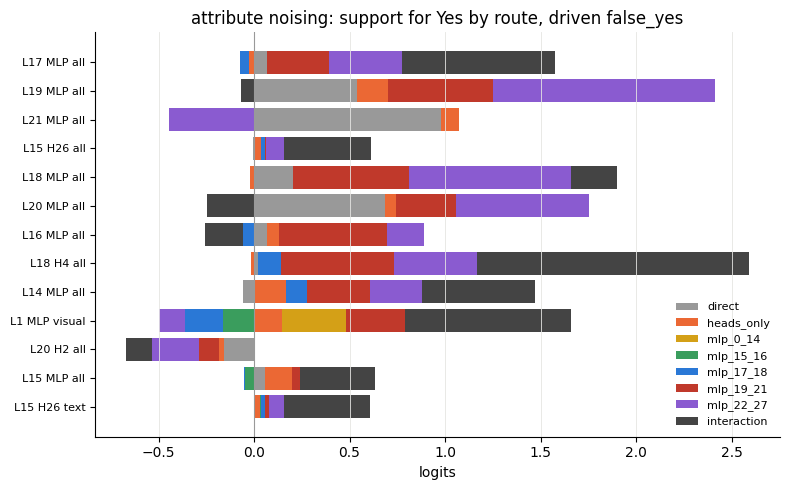

===== relation: false_yes 100 questions, true_yes controls 100 =====
--- noising: mean support for Yes by route on driven false_yes (logits). total = direct + heads_only + the five MLP windows + interaction ---
               total  direct  heads_only  mlp_0_14  mlp_15_16  mlp_17_18  mlp_19_21  mlp_22_27  interaction
L15 H26 text   0.189   0.000       0.026     0.000     -0.004     -0.002     -0.034      0.021        0.182
L15 MLP all    0.448   0.049       0.052     0.000     -0.032      0.016     -0.040      0.031        0.373
L20 H2 all    -0.621  -0.078      -0.004     0.000      0.000      0.000     -0.054     -0.165       -0.319
L1 MLP visual  0.640   0.000       0.281    -0.024     -0.211     -0.057     -0.052     -0.085        0.788
L14 MLP all    0.381  -0.091       0.155     0.000     -0.004      0.030      0.085      0.109        0.096
L18 H4 all     0.690   0.014      -0.007     0.000      0.000      0.070      0.121      0.106        0.387
L16 MLP all    0.678  -0.005     

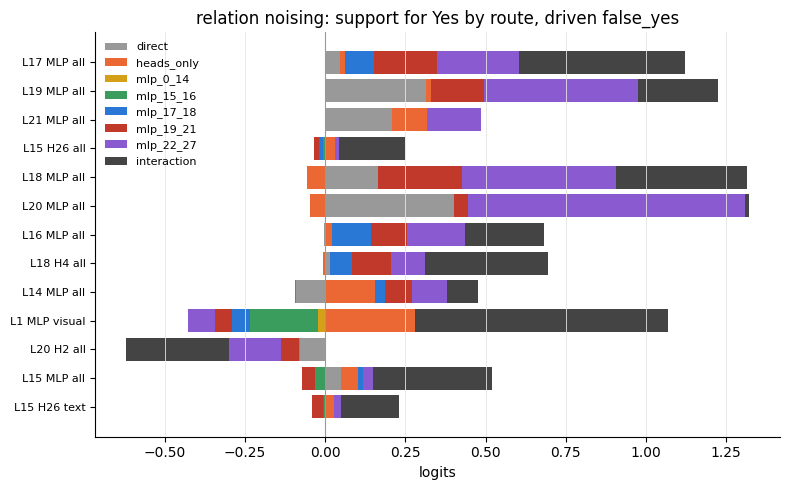

    [upload ok] summary


In [8]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "P_batch_*.pt")), key=batch_number):
    entries.extend(torch.load(path))
good_all = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good_all}) == len(good_all), "duplicated entries"
print(f"{len(entries)} entries, {len(good_all)} ok, {len(stage_ids) - len(good_all)} stage questions not done")


def summarize(htype):
    good = [e for e in good_all if e["hallu_type"] == htype]
    if len(good) < 10:
        print(f"{htype}: only {len(good)} entries, skipped")
        return None
    E = np.stack([e["effects"].numpy() for e in good])
    sign = np.array([e["sign"] for e in good])
    role = np.array([e["stratum"] for e in good])
    uid = np.array([e["uid"] for e in good])
    SUP = np.empty_like(E)
    for di, dname in enumerate(DIRECTIONS):
        SUP[:, di] = (-sign if dname == "noising" else sign)[:, None, None] * E[:, di]
    k = {n: i for i, n in enumerate(SET_NAMES)}


    PARTS = list(WINDOWS)


    def routes(S):
        g = lambda name: S[..., k[name]]
        out = {"total": g("total"), "direct": g("direct"), "heads_only": g("heads_all") - g("direct")}
        for part in PARTS:
            out[f"mlp_{part}"] = g(f"heads_{part}") - g("heads_all")
        out["interaction"] = g("total") - g("heads_all") - sum(out[f"mlp_{part}"] for part in PARTS)
        return out


    R = routes(SUP)
    fy = role == "false_yes"
    ct = role == "true_yes"
    print(f"===== {htype}: false_yes {int(fy.sum())} questions, true_yes controls {int(ct.sum())} =====")
    cols = ["total", "direct", "heads_only"] + [f"mlp_{x}" for x in PARTS] + ["interaction"]
    for di, dname in enumerate(DIRECTIONS):
        table = pd.DataFrame({c: R[c][fy, di].mean(0) for c in cols}, index=SENDER_NAMES)
        print(f"--- {dname}: mean support for Yes by route on driven false_yes (logits). total = direct + heads_only + the five MLP windows + interaction ---")
        print(table.round(3).to_string())

    pairs = sorted(set(uid[fy]) & set(uid[ct]))
    fy_ix = {u: i for i, u in enumerate(uid) if fy[i]}
    ct_ix = {u: i for i, u in enumerate(uid) if ct[i]}
    a_ix = np.array([fy_ix[u] for u in pairs])
    b_ix = np.array([ct_ix[u] for u in pairs])
    boot = np.random.default_rng(1).integers(0, len(pairs), size=(1000, len(pairs)))


    def contrast(name, di):
        diff = R[name][a_ix, di] - R[name][b_ix, di]
        means = diff[boot].mean(1)
        return diff.mean(0), np.percentile(means, 2.5, axis=0), np.percentile(means, 97.5, axis=0)


    print(f"--- false_yes minus matched true_yes over {len(pairs)} units: mean [95% interval over units] ---")
    for di, dname in enumerate(DIRECTIONS):
        rows = {}
        for name in ["total", "heads_only"] + [f"mlp_{x}" for x in PARTS] + ["interaction"]:
            m, lo, hi = contrast(name, di)
            rows[name] = [f"{m[i]:+.3f} [{lo[i]:+.3f}, {hi[i]:+.3f}]" for i in range(len(SENDERS))]
        print(dname)
        print(pd.DataFrame(rows, index=SENDER_NAMES).to_string())

    print("--- routers: which MLP windows carry a separate effect (interval over units excludes 0 and |mean| >= 0.05)? ---")
    verdict = {}
    for di, dname in enumerate(DIRECTIONS):
        for name in ROUTER_NAMES:
            i = SENDER_NAMES.index(name)
            present, detail = [], {}
            for part in PARTS:
                m, lo, hi = (x[i] for x in contrast(f"mlp_{part}", di))
                detail[part] = float(m)
                if (lo > 0 or hi < 0) and abs(m) >= 0.05:
                    present.append(f"{part} ({m:+.3f})")
            mt = contrast("total", di)[0][i]
            verdict[f"{dname}/{name}"] = {"total": float(mt), "windows": detail, "present": present}
            print(f"{dname:10s} {name:14s} total {mt:+.3f} | routes present: {', '.join(present) if present else 'none'} | {len(present)} windows")

    BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
    GREEN2, PURPLE, RED = "#8a5bd0", "#d4a017", "#c0392b"
    parts = [("direct", GREY), ("heads_only", ORANGE), ("mlp_0_14", PURPLE), ("mlp_15_16", GREEN), ("mlp_17_18", BLUE), ("mlp_19_21", RED), ("mlp_22_27", GREEN2), ("interaction", "#444444")]
    fig, axes = plt.subplots(1, len(DIRECTIONS), figsize=(8 * len(DIRECTIONS), 5), sharey=True)
    axes = np.atleast_1d(axes)
    for di, dname in enumerate(DIRECTIONS):
        pos_ = np.zeros(len(SENDERS))
        neg_ = np.zeros(len(SENDERS))
        for name, color in parts:
            v = R[name][fy, di].mean(0)
            base_ = np.where(v >= 0, pos_, neg_)
            axes[di].barh(np.arange(len(SENDERS)), v, left=base_, color=color, label=name)
            pos_ += np.where(v >= 0, v, 0)
            neg_ += np.where(v < 0, v, 0)
        axes[di].set_yticks(np.arange(len(SENDERS)))
        axes[di].set_yticklabels(SENDER_NAMES, fontsize=8)
        axes[di].axvline(0, color=GREY, lw=0.8)
        axes[di].set_title(f"{htype} {dname}: support for Yes by route, driven false_yes")
        axes[di].set_xlabel("logits")
        axes[di].grid(color="#e5e5e2", lw=0.6, axis="x")
        axes[di].spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"qwen_path_routes_{htype}.png"), dpi=150)
    plt.show()
    return {
        "n_ok": len(good), "n_pairs": len(pairs), "verdict": verdict,
        "mean_routes_false_yes": {dname: {c: R[c][fy, di].mean(0).tolist() for c in R} for di, dname in enumerate(DIRECTIONS)},
    }


summaries = {htype: summarize(htype) for htype in HALLU_TYPES}
with open(os.path.join(OUT_DIR, "path_summary.json"), "w") as f:
    json.dump({"sender_names": SENDER_NAMES, "summaries": summaries}, f)
if not upload("summary"):
    print(f"final upload failed; the batch files and summary are still in {OUT_DIR}, which is saved as this notebook's output")